This cleaning process includes check for the start condon and end condon.

In [1]:
from pathlib import Path

def find_repo_root(marker="pyproject.toml"):
    p = Path.cwd()
    for _ in range(5):
        if (p / marker).exists():
            return p
        p = p.parent
    raise RuntimeError("Repo root not found")

REPO_ROOT = find_repo_root()

# repo 的上一层：workspace
WORKSPACE_ROOT = REPO_ROOT.parent

# 数据目录（明确指向 repo 外）
DATA_RAW = WORKSPACE_ROOT / "data_raw"
DATA_CACHE = WORKSPACE_ROOT / "data_cache"

print("REPO_ROOT:", REPO_ROOT)
print("WORKSPACE_ROOT:", WORKSPACE_ROOT)
print("DATA_RAW exists:", DATA_RAW.exists())

REPO_ROOT: /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/Sequence-Optimization-with-CodonBERT
WORKSPACE_ROOT: /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT
DATA_RAW exists: True


In [2]:
from Bio import SeqIO

for seq_record in SeqIO.parse(DATA_RAW/ "oligos.fasta", "fasta"):
    print(seq_record.id)
    print(repr(seq_record.seq))
    print(len(seq_record))
    break

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
GFP_1_1L_GC0
Seq('ctraayttrtgnccrttbacrtcnccrtcyaaytcnacnagdatnggnacnac')
53


In [3]:
import pandas as pd
import re

def clean_iupac_fasta_to_df(input_fasta):
    """
    
    Read FASTA and expand degenerate repeats like (N20) -> 'A'*20.
    Replace IUPAC ambiguous bases with representative A/T/C/G.
    Return DataFrame with ['id', 'original_seq', 'clean_seq'].
    """

    mapping = {
        'R': 'A', 'Y': 'C', 'D': 'A',
        'H': 'A', 'N': 'A'
    }

    def expand_repeats(seq):
        """
        Replace patterns like (N20) with 'A'*20 based on mapping.
        """
        def repl(match):
            base = match.group(1)
            num = int(match.group(2))
            base_clean = mapping.get(base, base)
            return base_clean * num

        # Expand (X20) patterns
        seq = re.sub(r"\(([A-Z])(\d+)\)", repl, seq)

        # Remove leftover parentheses or numbers (just in case)
        seq = re.sub(r"[\(\)\d]", "", seq)
        # Replace IUPAC ambiguity codes
        seq = ''.join(mapping.get(b, b) for b in seq)
        return seq

    records = []
    for record in SeqIO.parse(input_fasta, "fasta"):
        seq_str = str(record.seq).upper()
        cleaned_seq = expand_repeats(seq_str)
        records.append({
            "id": record.id,
            "original_seq": seq_str,
            "clean_seq": cleaned_seq
        })

    df = pd.DataFrame(records)
    print(f"✅ Cleaned and expanded {len(df)} sequences from {input_fasta}")
    return df

clean_iupac_fasta_to_df(DATA_RAW / "oligos.fasta")


✅ Cleaned and expanded 82 sequences from /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/data_raw/oligos.fasta


,id,original_seq,clean_seq
0,GFP_1_1L_GC0,CTRAAYTTRTGNCCRTTBACRTCNCCRTCYAAYTCNACNAGDATNG...,CTAAACTTATGACCATTBACATCACCATCCAACTCAACAAGAATAG...
1,GFP_1_1L_yCAI+,CTGAACTTGTGACCGTTGACRTCACCRTCCAATTCRACTAGRATTG...,CTGAACTTGTGACCGTTGACATCACCATCCAATTCAACTAGAATTG...
2,GFP_1_1U_EcCAI+,ATGGTWAGCAAAGGYGAAGAACTGTTCACYGGYGTWGTWCCGATCC...,ATGGTWAGCAAAGGCGAAGAACTGTTCACCGGCGTWGTWCCGATCC...
3,GFP_1_1U_GC-,ATGGTWAGTAAAGGWGARGAACTWTTTACWGGWGTWGTWCCWATWC...,ATGGTWAGTAAAGGWGAAGAACTWTTTACWGGWGTWGTWCCWATWC...
4,GFP_1_1U_GC+,ATGGTSAGCAAGGGSGAGGARCTSTTCACSGGSGTSGTSCCSATYC...,ATGGTSAGCAAGGGSGAGGAACTSTTCACSGGSGTSGTSCCSATCC...
...,...,...,...
77,GFP_3_3U_EcCAI+,TCYAAAGACCCGAACGAAAAAAGAGAYCACATGGTWCTGCTGGAGT...,TCCAAAGACCCGAACGAAAAAAGAGACCACATGGTWCTGCTGGAGT...
78,GFP_3_3U_GC-,TC(N20)AA(R20)GACCC(N20)AA(Y20)GA(R20)AA(R20)A...,TCAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAGA...
79,GFP_3_3U_GC+,TC(N80)AA(R80)GACCC(N80)AA(Y80)GA(R80)AA(R80)A...,TCAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA...
80,GFP_3_3U_GC0,TCNAARGACCCNAAYGARAARAGRGAYCAYATGGTNCTNTTRGAGT...,TCAAAAGACCCAAACGAAAAAAGAGACCACATGGTACTATTAGAGT...


In [4]:
def save_clean_fasta(df, output_path, seq_col='clean_seq', id_col='id'):
    """
    Save cleaned sequences from DataFrame to FASTA file.
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with sequence data
    output_path : str or Path
        Output FASTA file path
    seq_col : str
        Column name containing the sequences
    id_col : str
        Column name containing the sequence IDs
    """
    from Bio.SeqRecord import SeqRecord
    from Bio.Seq import Seq
    
    records = []
    for _, row in df.iterrows():
        seq_record = SeqRecord(
            Seq(row[seq_col]),
            id=row[id_col],
            description=""
        )
        records.append(seq_record)
    
    SeqIO.write(records, str(output_path), "fasta")
    print(f"✅ Saved {len(records)} sequences to {output_path}")

# Clean and save
df_oligos = clean_iupac_fasta_to_df(DATA_RAW / "oligos.fasta")
save_clean_fasta(df_oligos, DATA_CACHE / "oligos_clean.fasta")

✅ Cleaned and expanded 82 sequences from /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/data_raw/oligos.fasta
✅ Saved 82 sequences to /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/data_cache/oligos_clean.fasta


In [5]:
def validate_codon_sequence_oligos(seq, slide_step=1):
    """
    Validate DNA sequence based on Kudla et al. (Science 2009) setup.
    - Start codon: ATG (first valid one found in frame)
    - Stop codon: TAA (first valid one found after start)
    - Coding region (between start and stop) must be multiple of 3
    
    Returns
    -------
    dict with keys:
        valid: bool
        reason: str
        start_index: int or None
        stop_index: int or None
        coding_length: int
        start_codon: str or None
        stop_codon: str or None
    """
    START_CODONS = ["ATG"]
    STOP_CODONS = ["TAA"]

    seq = seq.strip().upper()
    start_index = stop_index = None

    # --- find start codon (slide_step=1 or 3)
    for i in range(0, len(seq) - 2, slide_step):
        codon = seq[i:i+3]
        if codon in START_CODONS:
            start_index = i
            break

    if start_index is None:
        return {"valid": False, "reason": "No start codon found."}

    # --- find stop codon
    for j in range(start_index + 3, len(seq) - 2, 3):
        codon = seq[j:j+3]
        if codon in STOP_CODONS:
            stop_index = j
            break

    if stop_index is None:
        return {
            "valid": False,
            "reason": "No in-frame stop codon found after start.",
            "start_index": start_index,
            "start_codon": seq[start_index:start_index+3]
        }

    coding_len = stop_index - start_index - 3
    return {
        "valid": True,
        "reason": "Valid ORF found.",
        "start_index": start_index,
        "stop_index": stop_index,
        "coding_length": coding_len,
        "start_codon": seq[start_index:start_index+3],
        "stop_codon": seq[stop_index:stop_index+3]
    }


In [6]:
validate_codon_sequence_oligos('CTAAACTTATGACCATTBACATCACCATCCAACTCAACAAGAATAGGAACAAC')

{'valid': False,
 'reason': 'No in-frame stop codon found after start.',
 'start_index': 8,
 'start_codon': 'ATG'}

In [7]:
def screen_fasta_for_df_oligos(df, slide_step=1):
    """
    Take a DataFrame with 'clean_seq' column,
    apply validate_codon_sequence_kudla() to each sequence,
    return enriched DataFrame with validation info.
    """
    results = []
    for _, row in df.iterrows():
        res = validate_codon_sequence_oligos(row["clean_seq"], slide_step=slide_step)
        res["id"] = row["id"]
        res["seq_len"] = len(row["clean_seq"])
        results.append(res)
    
    df_out = pd.DataFrame(results)
    print(f"✅ ORF screening complete: {len(df_out)} sequences processed")
    print(df_out["valid"].value_counts())
    return df_out


In [8]:
df_clean = clean_iupac_fasta_to_df(DATA_RAW / "oligos.fasta")

# SCREEN FOR STARTERS AND STOPPERS
df_valid = screen_fasta_for_df_oligos(df_clean, slide_step=3)

# 
# df_oligos = df_clean.merge(df_valid[df_valid["valid"] == True][["id", "valid", "start_index", "stop_index"]], on="id", how="inner")
df_oligos = df_clean.merge(df_valid[["id", "valid", "start_index", "stop_index"]], on="id", how="inner")

print('Valid sequences in df_oligos:', len(df_oligos))
df_oligos.head()

✅ Cleaned and expanded 82 sequences from /Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/data_raw/oligos.fasta
✅ ORF screening complete: 82 sequences processed
valid
False    77
True      5
Name: count, dtype: int64
Valid sequences in df_oligos: 82


,id,original_seq,clean_seq,valid,start_index,stop_index
0,GFP_1_1L_GC0,CTRAAYTTRTGNCCRTTBACRTCNCCRTCYAAYTCNACNAGDATNG...,CTAAACTTATGACCATTBACATCACCATCCAACTCAACAAGAATAG...,False,NaN,NaN
1,GFP_1_1L_yCAI+,CTGAACTTGTGACCGTTGACRTCACCRTCCAATTCRACTAGRATTG...,CTGAACTTGTGACCGTTGACATCACCATCCAATTCAACTAGAATTG...,False,NaN,NaN
2,GFP_1_1U_EcCAI+,ATGGTWAGCAAAGGYGAAGAACTGTTCACYGGYGTWGTWCCGATCC...,ATGGTWAGCAAAGGCGAAGAACTGTTCACCGGCGTWGTWCCGATCC...,False,0.0,NaN
3,GFP_1_1U_GC-,ATGGTWAGTAAAGGWGARGAACTWTTTACWGGWGTWGTWCCWATWC...,ATGGTWAGTAAAGGWGAAGAACTWTTTACWGGWGTWGTWCCWATWC...,False,0.0,NaN
4,GFP_1_1U_GC+,ATGGTSAGCAAGGGSGAGGARCTSTTCACSGGSGTSGTSCCSATYC...,ATGGTSAGCAAGGGSGAGGAACTSTTCACSGGSGTSGTSCCSATCC...,False,0.0,NaN


In [9]:

import torch
import pandas as pd
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForPreTraining

def get_codon_outputs(seq, tokenizer, model, max_len=512, device="cpu"):
    """
    Run CodonBERT on a single DNA sequence and return both MLM logits and embeddings.
    """
    # Tokenize
    inputs = tokenizer(
        seq,
        return_tensors="pt",
        truncation=True,
        #padding='max_length'
        padding = True,
        max_length=max_len
    ).to(device)

    with torch.no_grad():
        # Explicitly ask for hidden states
        outputs = model(**inputs, output_hidden_states=True)

    # Masked language modeling logits
    mlm_logits = outputs.prediction_logits.squeeze(0).cpu()

    # Embeddings from the last hidden layer
    if outputs.hidden_states is not None:
        embeddings = outputs.hidden_states[-1].squeeze(0).cpu()
    else:
        embeddings = model.bert(**inputs).last_hidden_state.squeeze(0).cpu()

    return mlm_logits, embeddings


def compute_embeddings_for_df(df, seq_col="clean_seq", model_name="lhallee/CodonBERT", batch_size=8, device=None):
    """
    Compute CodonBERT embeddings for all sequences in a DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing DNA sequences.
    seq_col : str, optional
        Name of the column that stores DNA sequences. Default is "clean_seq".
    model_name : str, optional
        Name or path of the pretrained model to use. Default is "lhallee/CodonBERT".
    batch_size : int, optional
        Number of sequences processed at once. Larger batch size increases speed 
        but also memory/GPU usage. Default is 8.
    device : str, optional
        Device to use for computation ("cuda" or "cpu"). If None, automatically 
        selects GPU if available, otherwise CPU.

    Returns
    -------
    pandas.DataFrame
        A copy of the input DataFrame with an additional column `embedding`, 
        where each entry is a tensor of shape [seq_len, hidden_dim] representing 
        the CodonBERT embeddings for that sequence.
    """
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForPreTraining.from_pretrained(model_name).to(device)
    model.eval()

    mlm_logits= []
    all_embeddings = []
    
    for seq in tqdm(df[seq_col], desc="Embedding sequences"):
        mlm,emb = get_codon_outputs(seq, tokenizer, model, device=device)
        all_embeddings.append(emb)
        mlm_logits.append(mlm)
    df_out = df[['id','clean_seq']].copy()
    df_out["MLM"] = mlm_logits
    df_out["embedding"] = all_embeddings
    return df_out


In [10]:
df_with_emb = compute_embeddings_for_df(df_oligos)

Embedding sequences: 100%|██████████| 82/82 [00:04<00:00, 18.75it/s]


In [11]:
df_with_emb.head()

,id,clean_seq,MLM,embedding
0,GFP_1_1L_GC0,CTAAACTTATGACCATTBACATCACCATCCAACTCAACAAGAATAG...,"[[tensor(-15.7336), tensor(-13.6617), tensor(-...","[[tensor(0.2680), tensor(-0.1236), tensor(0.07..."
1,GFP_1_1L_yCAI+,CTGAACTTGTGACCGTTGACATCACCATCCAATTCAACTAGAATTG...,"[[tensor(-15.7336), tensor(-13.6617), tensor(-...","[[tensor(0.2680), tensor(-0.1236), tensor(0.07..."
2,GFP_1_1U_EcCAI+,ATGGTWAGCAAAGGCGAAGAACTGTTCACCGGCGTWGTWCCGATCC...,"[[tensor(-15.7336), tensor(-13.6617), tensor(-...","[[tensor(0.2680), tensor(-0.1236), tensor(0.07..."
3,GFP_1_1U_GC-,ATGGTWAGTAAAGGWGAAGAACTWTTTACWGGWGTWGTWCCWATWC...,"[[tensor(-15.7336), tensor(-13.6617), tensor(-...","[[tensor(0.2680), tensor(-0.1236), tensor(0.07..."
4,GFP_1_1U_GC+,ATGGTSAGCAAGGGSGAGGAACTSTTCACSGGSGTSGTSCCSATCC...,"[[tensor(-15.7336), tensor(-13.6617), tensor(-...","[[tensor(0.2680), tensor(-0.1236), tensor(0.07..."


In [12]:
df_with_emb['embedding'][0]

tensor([[ 0.2680, -0.1236,  0.0787,  ..., -0.1736, -0.9255,  0.1316],
        [ 0.2702, -0.2250,  0.3532,  ...,  0.1391, -1.0764,  0.5688],
        [ 0.5499, -0.4428,  0.3693,  ...,  0.2403, -0.6261,  0.5298]])

In [13]:
print("MLM logits shape:", df_with_emb['MLM'][0].shape)
print("Embeddings shape:", df_with_emb['embedding'][0].shape)

MLM logits shape: torch.Size([3, 69])
Embeddings shape: torch.Size([3, 768])


Explained variance ratio: [1.0000014e+00 8.4455414e-18]


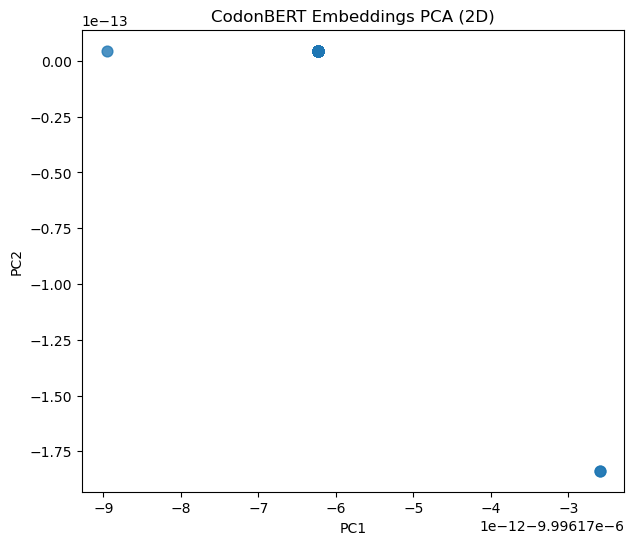

In [14]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

# === Step 1. Mean pooling each sequence embedding to [768] ===
df_with_emb["embedding_mean"] = [emb.mean(dim=0) for emb in df_with_emb["embedding"]]

# === Step 2. Stack into a matrix for PCA ===
X = torch.stack(df_with_emb["embedding_mean"].tolist()).numpy()  # shape [n_seq, 768]

# === Step 3. PCA (choose 2D or 3D) ===
pca_dim = 2   # 改成 2 就画 2D
pca = PCA(n_components=pca_dim)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_)

# === Step 4. Plot ===
if pca_dim == 2:
    plt.figure(figsize=(7,6))
    plt.scatter(X_pca[:,0], X_pca[:,1], s=60, alpha=0.8)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("CodonBERT Embeddings PCA (2D)")
    plt.show()

elif pca_dim == 3:
    fig = plt.figure(figsize=(8,7))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], s=60, alpha=0.8)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title("CodonBERT Embeddings PCA (3D)")
    plt.show()


In [15]:
X_pca

array([[-9.9961790e-06,  4.6004799e-15],
       [-9.9961762e-06,  4.5931442e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.9961762e-06,  4.5931251e-15],
       [-9.99617

In [16]:
df_with_emb["embedding_mean"]

0     [tensor(0.3627), tensor(-0.2638), tensor(0.267...
1     [tensor(0.3627), tensor(-0.2638), tensor(0.267...
2     [tensor(0.3627), tensor(-0.2638), tensor(0.267...
3     [tensor(0.3627), tensor(-0.2638), tensor(0.267...
4     [tensor(0.3627), tensor(-0.2638), tensor(0.267...
                            ...                        
77    [tensor(0.3627), tensor(-0.2638), tensor(0.267...
78    [tensor(0.3627), tensor(-0.2638), tensor(0.267...
79    [tensor(0.3627), tensor(-0.2638), tensor(0.267...
80    [tensor(0.3627), tensor(-0.2638), tensor(0.267...
81    [tensor(0.3627), tensor(-0.2638), tensor(0.267...
Name: embedding_mean, Length: 82, dtype: object

In [17]:
X_pca[:,0]


array([-9.996179e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e-06,
       -9.996176e-06, -9.996176e-06, -9.996176e-06, -9.996176e